# 04 · Baselines and first models

Reads the output of `fraud models compare` (trained on 2024-10-01 → 2025-06-30, evaluated on
validation 2025-07-01 → 2025-09-30; test not touched). Default hyperparameters: tuning is
Phase 7.

Questions:
1. Does machine learning beat simple rules, and by how much?
2. Are the differences between models real or noise?
3. What do class weights do?
4. How much of the performance comes from signals the simulator made artificially strong?

In [1]:
from datetime import timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix

from fraudplatform.config import PROJECT_ROOT, load_feature_config, load_model_config, load_splits
from fraudplatform.db import connect
from fraudplatform.eda import plots
from fraudplatform.eda.data import load_features
from fraudplatform.models import baselines, pipelines
from fraudplatform.models.comparison import prepare, summary_table
from fraudplatform.models.metrics import bootstrap_pr_auc_difference, evaluate, top_k_mask
from fraudplatform.models.report import plot_pr_curves

plots.apply_style()
pd.set_option("display.width", 160)

run_dir = PROJECT_ROOT / "data" / "processed" / "phase6"
scores = pd.read_parquet(run_dir / "validation_scores.parquet")
results = pd.read_csv(run_dir / "results.csv")
cfg, feature_cfg, splits = load_model_config(), load_feature_config(), load_splits()
y = scores["is_fraud"].to_numpy()
days = scores["ts"].dt.date.to_numpy()
alert_rate = cfg.evaluation.alert_rate
print(f"validation: {len(scores):,} transactions, {y.sum():,} fraud ({y.mean():.3%})")
print(
    f"alert budget {alert_rate:.1%} -> {int(np.ceil(alert_rate * len(y))):,} alerts; "
    f"best possible recall = {np.ceil(alert_rate * len(y)) / y.sum():.1%}"
)

validation: 359,220 transactions, 2,608 fraud (0.726%)
alert budget 0.5% -> 1,797 alerts; best possible recall = 68.9%


## 1. Comparison on validation

In [2]:
summary_table(results).style.format(
    {
        "pr_auc": "{:.4f}",
        "roc_auc": "{:.4f}",
        "brier": "{:.4f}",
        "mean_predicted": "{:.4f}",
        "precision_at_alert_rate": "{:.1%}",
        "recall_at_alert_rate": "{:.1%}",
        "amount_recall_at_alert_rate": "{:.1%}",
        "fit_seconds": "{:.0f}",
    },
    na_rep="",
)

,candidate,pr_auc,pr_auc_95ci,roc_auc,precision_at_alert_rate,recall_at_alert_rate,amount_recall_at_alert_rate,brier,mean_predicted,fit_seconds
0,B0_approve_all,0.0073,0.007 – 0.008,0.5000,0.3%,0.2%,0.1%,,,0
1,B1_amount,0.0255,0.022 – 0.030,0.7148,5.3%,3.6%,30.4%,,,0
2,B2_expert_rules,0.2556,0.235 – 0.283,0.7899,46.3%,31.9%,31.8%,,,0
3,M1_logistic_regression,0.7663,0.745 – 0.792,0.9414,88.4%,60.9%,79.8%,0.0026,0.0072,21
4,M1b_logistic_regression_balanced,0.7208,0.697 – 0.751,0.9492,83.9%,57.8%,70.6%,0.0320,0.1233,30
5,M2_random_forest,0.7646,0.736 – 0.794,0.9443,89.0%,61.3%,75.5%,0.0027,0.0081,86
6,M3_hist_gradient_boosting,0.7901,0.768 – 0.816,0.9545,91.8%,63.2%,83.8%,0.0023,0.0072,18
7,M3b_hist_gradient_boosting_balanced,0.7880,0.764 – 0.812,0.9528,89.0%,61.3%,79.2%,0.0121,0.0684,20


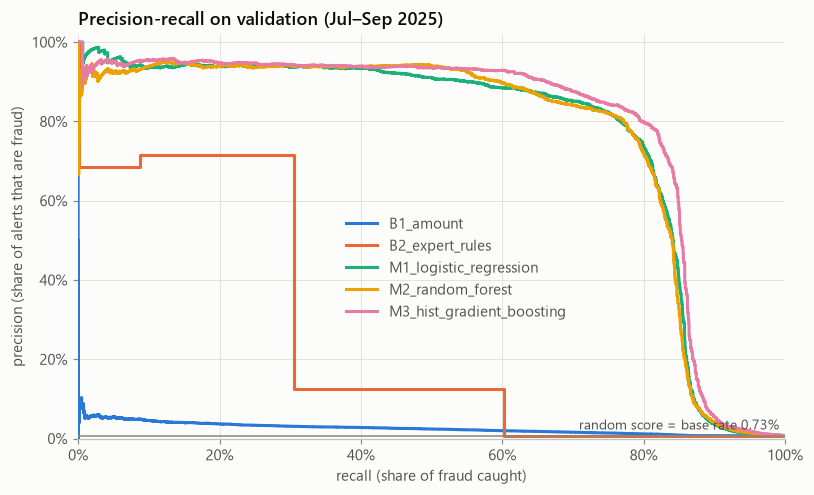

In [3]:
fig = plot_pr_curves(scores, "Precision-recall on validation (Jul–Sep 2025)")
plt.show()

## 2. Reading the metrics on the best model

**Confusion matrix** at the alert budget (flag the top 0.5% of scores) and at the
"default" 0.5 probability threshold. The two flag a different number of transactions:
0.5 is a convention that ignores both review capacity and the cost of each error. Here it
happens to flag MORE than the budget allows (2,268 vs 1,797 alerts), with lower precision.
Phase 8 chooses thresholds from costs and capacity instead.

In [4]:
best = "M3_hist_gradient_boosting"
p = scores[best].to_numpy()
for label, flagged in [
    (f"top {alert_rate:.1%} of scores", top_k_mask(p, int(np.ceil(alert_rate * len(p))))),
    ("probability >= 0.5", p >= 0.5),
]:
    tn, fp, fn, tp = confusion_matrix(y, flagged).ravel()
    display(
        pd.DataFrame(
            [[tn, fp], [fn, tp]],
            index=["actual legit", "actual fraud"],
            columns=["not flagged", "flagged"],
        ).style.set_caption(
            f"{label}: precision {tp / max(tp + fp, 1):.1%}, recall {tp / (tp + fn):.1%}, "
            f"false positive rate {fp / (fp + tn):.3%}"
        )
    )

,not flagged,flagged
actual legit,356464,148
actual fraud,959,1649


,not flagged,flagged
actual legit,356270,342
actual fraud,682,1926


**ROC-AUC vs PR-AUC.** The expert rules have a respectable-looking ROC-AUC (0.79) but a
PR-AUC of 0.26. ROC-AUC rewards ranking a random fraud above a random legit payment, and
with 117 legit payments per fraud there are so many easy legit ones that a weak ranking
still scores well. PR-AUC asks what share of the *alerts* are fraud: the question the
review team cares about.

## 3. Are the differences real? Paired day-block bootstrap

Both models are scored on the same resampled days, so the comparison removes the
day-to-day noise that makes separate intervals overlap.

In [5]:
pairs = [
    ("M3_hist_gradient_boosting", "M1_logistic_regression"),
    ("M3_hist_gradient_boosting", "M2_random_forest"),
    ("M1_logistic_regression", "M2_random_forest"),
    ("M1_logistic_regression", "B2_expert_rules"),
    ("M3_hist_gradient_boosting", "M3b_hist_gradient_boosting_balanced"),
    ("M1_logistic_regression", "M1b_logistic_regression_balanced"),
]
rows = []
for a, b in pairs:
    out = bootstrap_pr_auc_difference(y, scores[a], scores[b], days, reps=300, seed=11)
    rows.append({"a": a, "b": b, **out})
pd.DataFrame(rows).style.format(
    {"difference": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "share_a_better": "{:.1%}"}
)

,a,b,difference,ci_low,ci_high,share_a_better
0,M3_hist_gradient_boosting,M1_logistic_regression,+0.0238,+0.0150,+0.0331,100.0%
1,M3_hist_gradient_boosting,M2_random_forest,+0.0255,+0.0145,+0.0354,100.0%
2,M1_logistic_regression,M2_random_forest,+0.0017,-0.0074,+0.0120,58.7%
3,M1_logistic_regression,B2_expert_rules,+0.5108,+0.4893,+0.5278,100.0%
4,M3_hist_gradient_boosting,M3b_hist_gradient_boosting_balanced,+0.0021,-0.0066,+0.0098,73.3%
5,M1_logistic_regression,M1b_logistic_regression_balanced,+0.0456,+0.0345,+0.0577,100.0%


## 4. Class weights: ranking barely changes, probabilities break

`class_weight="balanced"` makes each fraud count ~140× in the loss. It is the common answer
to imbalance, and resampling (SMOTE, undersampling) has the same effect on the
probabilities. What it does NOT do is add information.

In [6]:
def reliability(score: np.ndarray, bins: int = 10) -> pd.DataFrame:
    edges = np.quantile(score, np.linspace(0, 1, bins + 1))
    bucket = np.clip(np.searchsorted(edges, score, side="right") - 1, 0, bins - 1)
    frame = pd.DataFrame({"bucket": bucket, "predicted": score, "observed": y})
    return frame.groupby("bucket").agg(
        predicted=("predicted", "mean"), observed=("observed", "mean"), n=("observed", "size")
    )


for model in [
    "M3_hist_gradient_boosting",
    "M3b_hist_gradient_boosting_balanced",
    "M1_logistic_regression",
    "M1b_logistic_regression_balanced",
]:
    r = reliability(scores[model].to_numpy())
    print(f"{model}: mean predicted {scores[model].mean():.4f} vs observed {y.mean():.4f}")
    display(r.tail(3).style.format({"predicted": "{:.3f}", "observed": "{:.3f}"}))

M3_hist_gradient_boosting: mean predicted 0.0072 vs observed 0.0073


,predicted,observed,n
bucket,,,
7,0.001,0.002,35922
8,0.002,0.002,35922
9,0.065,0.065,35922


M3b_hist_gradient_boosting_balanced: mean predicted 0.0684 vs observed 0.0073


,predicted,observed,n
bucket,,,
7,0.077,0.001,35922
8,0.110,0.002,35922
9,0.298,0.065,35922


M1_logistic_regression: mean predicted 0.0072 vs observed 0.0073


,predicted,observed,n
bucket,,,
7,0.001,0.001,35922
8,0.002,0.002,35922
9,0.066,0.064,35922


M1b_logistic_regression_balanced: mean predicted 0.1233 vs observed 0.0073


,predicted,observed,n
bucket,,,
7,0.146,0.001,35922
8,0.212,0.002,35922
9,0.481,0.064,35922


## 5. Anatomy of the expert rules

Each rule on its own: how often it fires and how precise it is.

In [7]:
with connect() as conn:
    valid = prepare(load_features(conn, splits.validation.start, splits.validation.end))
flags = baselines.rule_flags(valid, cfg.rules)
definitions = baselines.rule_definitions(cfg.rules)
rule_rows = []
for name in flags:
    fired = flags[name].to_numpy()
    tp = int((fired & valid["is_fraud"].to_numpy()).sum())
    rule_rows.append(
        {
            "rule": name,
            "definition": definitions[name][0],
            "fires": int(fired.sum()),
            "precision": tp / max(fired.sum(), 1),
            "recall": tp / valid["is_fraud"].sum(),
        }
    )
any_rule = flags.any(axis=1).to_numpy()
tp_any = int((any_rule & valid["is_fraud"].to_numpy()).sum())
rule_rows.append(
    {
        "rule": "ANY rule",
        "definition": "",
        "fires": int(any_rule.sum()),
        "precision": tp_any / any_rule.sum(),
        "recall": tp_any / valid["is_fraud"].sum(),
    }
)
pd.DataFrame(rule_rows).style.format({"fires": "{:,}", "precision": "{:.1%}", "recall": "{:.1%}"})

,rule,definition,fires,precision,recall
0,burst,card used >= 2 times in the previous hour,703,64.7%,17.4%
1,card_testing,">= 1 micro-charge(s) in the previous hour, card not present",626,43.5%,10.4%
2,new_device_high_amount,first use of this device by the customer and amount > 200.0 EUR,561,39.6%,8.5%
3,cross_border_online,card-not-present payment from another country than the customer's,"10,346",10.1%,40.0%
4,impossible_travel,faster than a plane since the previous payment,45,33.3%,0.6%
5,device_many_cards,>= 2 distinct cards on the device in 24 h,536,62.3%,12.8%
6,night_risky_category,"night hours and category in ['gift_cards', 'luxury', 'electronics']","1,293",19.9%,9.9%
7,ANY rule,,"12,658",12.4%,60.2%


## 6. How much comes from signals the simulator made artificially strong?

The EDA flagged the device operating system and type as unrealistically informative (they
follow from the attacker device mix chosen in the simulator). Retrain the same gradient
boosting with both columns masked to a constant, so the model cannot use them.

In [8]:
masked_cols = ["operating_system", "device_type"]
with connect() as conn:
    train = prepare(
        load_features(
            conn,
            splits.train.start + timedelta(days=feature_cfg.warmup_days),
            splits.train.end,
        )
    )
columns = pipelines.model_columns("tree")
ablation = {}
for label, mask in [("all features", False), ("OS and device type masked", True)]:
    tr, va = train.copy(), valid.copy()
    if mask:
        for c in masked_cols:
            tr[c] = "masked"
            va[c] = "masked"
    model = pipelines.build_hist_gradient_boosting(
        cfg.models["hist_gradient_boosting"], random_state=cfg.random_state
    ).fit(tr[columns], tr["is_fraud"])
    s = model.predict_proba(va[columns])[:, 1]
    ablation[label] = s
    m = evaluate(va["is_fraud"], s, va["amount_eur"], va["ts"].dt.date, alert_rate, True)
    print(
        f"{label:28s} PR-AUC {m['pr_auc']:.4f}  recall@{alert_rate:.1%} "
        f"{m['recall_at_alert_rate']:.1%}"
    )
diff = bootstrap_pr_auc_difference(
    va["is_fraud"],
    ablation["all features"],
    ablation["OS and device type masked"],
    va["ts"].dt.date.to_numpy(),
    reps=300,
    seed=11,
)
diff

all features                 PR-AUC 0.7901  recall@0.5% 63.2%


OS and device type masked    PR-AUC 0.7833  recall@0.5% 62.8%


{'difference': 0.006791305889399357,
 'ci_low': 0.0011741858030564962,
 'ci_high': 0.012777768973153764,
 'share_a_better': 0.9833333333333333}

## 7. Findings

Full write-up: [`reports/models/phase6_findings.md`](../reports/models/phase6_findings.md).

- ML is far ahead of rules: PR-AUC 0.79 (gradient boosting) vs 0.26 (seven expert rules)
  vs 0.03 (amount alone). At the same 0.5% alert budget it catches 63.2% of fraud with
  91.8% precision; the rules catch 31.9% with 46.3% precision.
- Gradient boosting beats logistic regression by +0.024 PR-AUC (paired CI +0.015 to +0.033):
  real but modest. Logistic regression and random forest are indistinguishable.
- Class weights do not help ranking (and hurt logistic regression by 0.046) and inflate
  probabilities 9-17x. No class weights from here on.
- Masking the artificially strong device OS/type costs only 0.007 PR-AUC: the model does
  not depend on that simulator artefact, other device features carry the signal.
- These numbers are high because the data is synthetic and its fraud patterns are cleaner
  than real ones. The comparisons are the deliverable, not the absolute level.